# Predicting which coding bans a new AI model obeys

**A held-out-family test of Claim 3a on `google/gemma-3-4b-it`: can a ban-free "random-push" screen predict which coding bans a model obeys?**

Suppose a prompt bans a model's default algorithm: *"Do not use depth-first search (DFS) for this task."* The model either **obeys**, writing another algorithm from the task's catalogue, or **ignores** the ban and writes its default anyway. This experiment asks whether we can predict which of 15 coding tasks a model will obey on **before showing it any ban**. It uses Gemma, a model family this study had never run.

**The screen (the method)**
1. **Twin baseline.** For each task, Gemma writes 50 programs for a token-matched **neutral twin** prompt (*"Do not use house for this task."*). This gives its default algorithm `D` and its off-default share `p0`.
2. **Random pushes.** 8 fixed isotropic random directions × α ∈ {1, 2} are **written into the task-spec token states of blocks 11-22**, the middle third of 34, during the prompt prefill. The edit is *displacement-targeted*: the component along the direction is set to exactly α·n.
3. **Escape test.** A direction-α **escapes** if two conditions hold at N = 10:
   - it moves the model off its default: off-default share − p0 ≥ 0.20;
   - it keeps the pass rate: pass ≥ 0.8 × twin.

   It must also survive a 20-sample top-up (N = 30) with an exact binomial test.
4. **Prediction.** `E_t` = share of escaping directions. **MOVABLE** (`E_t > 0`) predicts that the model **obeys** a ban of its default (`A_t ≥ 0.5`).

All predictions were sha256 hash-chained (commit #2) before any ban prompt was built. Then 1,500 modal-ban programs were sampled. `A_t` is the share of ban answers that use another catalogue algorithm.

**What the experiment reported**
- **C3a is INCONCLUSIVE.** BA 0.739 [0.40, 0.95]; Fisher p 0.235; Spearman ρ 0.537 (one-sided permutation p 0.025).
- **Asking in words predicts better.** The off-default share under the novelty instruction has ρ 0.77.
- **C3b (landing forecasts) is INCONCLUSIVE.** Push-landing has the best log score (−0.11 vs −1.77 for association), but only 2 events disagree, fewer than the 3 the rule needs.
- **C1: temperature is not the creativity knob.** Within 5 pass points, plan noise (random pushes) raises correct-only algorithm diversity on several tasks (T2: Hill-1 1.0 → 1.62). Temperature 1.3/1.6 rarely changes the algorithm.
- **Post-hoc caveat on T2.** The frozen T2 labeller reads array-based Dijkstra as Bellman-Ford.

**What this notebook runs.** Generating the 10,730 programs needs a 16 GB GPU, the gated Gemma weights and about 1.3 GPU-hours, so this notebook does not repeat it. It runs on CPU, from the stored data:
1. shows the pipeline driver `method.py`; it can run the full pipeline from the repository with `RUN_FULL_PIPELINE = True`;
2. checks the push edit (`src/push.py`, verbatim) on a toy residual stack;
3. re-applies the frozen escape rule;
4. re-runs the **frozen, hash-committed analysis** (`predictions/analysis_c3.py`, verbatim) on the 15 task events: C3a with its sensitivities, rivals, C3b and C1;
5. compares every number with the values the experiment reported.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch -- pre-installed on Colab, install locally only (Colab's versions; CPU build of torch)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# method.py (pipeline driver)
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/analysis_c3.py (frozen analysis), src/final_analysis.py, src/predictors.py
import collections
import itertools
import math
from typing import Any

import numpy as np
from scipy import stats

# src/push.py (displacement-targeted push)
import contextlib
from typing import Callable, Iterator

import torch

# notebook additions: data loading and plots
import json
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/experiment-23/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print(f"dataset '{data['datasets'][0]['dataset']}': {len(data['datasets'][0]['examples'])} task events")

Curated demo subset of the held-out-family (gemma-3-4b-it) ban-prediction experiment: all 15 task-level events of the dataset heldout_task_events, each enriched with the per-task inputs that the frozen analysis reads (pre-ban commitment, C1 arm label counts, two sample-level A_t variants, example programs). Built by build_mini_demo_data.py.
dataset 'heldout_task_events': 15 task events


## Configuration

Every tunable value lives here. The resampling counts are set to the **experiment's original values**, and the analysis still takes only about half a minute on a CPU. They control the precision of the Monte-Carlo parts: permutation p-values, bootstrap CIs, placebos and rarefaction.

The point estimates do not depend on these counts: BA, Fisher p, ρ, Kendall τ, log scores and hull values. At the original counts, every seeded quantity reproduces the reported numbers exactly. The comments give the smallest tested values, for a quicker run.

In [5]:
# ---------------------------------------------------------------- frozen analysis (analysis_c3.py / final_analysis.py)
# All counts are the ORIGINAL values of the experiment; the analysis cells take ~30 s on a CPU. For a quicker look use
# the values in brackets (the smallest tested), which change only the precision of p-values, CIs and placebos.
N_PERM = 100_000      # permutations: Spearman p of the primary C3a test                     (quick: 1_000)
N_BOOT = 2_000        # task bootstrap: BA / rho CIs (C3a) and the rival delta-rho CIs         (quick: 100)
N_PLACEBO = 2_000     # task-label permutation placebo inside c3a                              (quick: 100)
N_PERM_SENS = 20_000  # permutations per sensitivity / post-hoc re-run of c3a                  (quick: 500)
N_BOOT_SENS = 1_000   # bootstraps per sensitivity / post-hoc re-run of c3a                    (quick: 50)
N_PLACEBO_C3B = 200   # shuffled-forecast placebo in c3b                                       (quick: 20)
N_SUB_RAREFY = 1_000  # rarefaction subsamples of the C1 correct-only Hill-1 (depth 25)        (quick: 100)
N_SUB_MC = 300        # Monte-Carlo draws per randomisation-hull point (mc_hill)               (quick: 50)
HULL_GRID = 21        # mixing weights per hull segment (hull_best)                            (quick: 11)
N_BOOT_HULL = 100     # bootstrap replicates of the C1 H5 CI (bootstrap_hull)                  (quick: 10)

# ---------------------------------------------------------------- toy check of the push edit (not Gemma)
TOY_P = 24            # prompt length of the toy batch
TOY_SPEC = (6, 20)    # task-spec positions [a, b) that the push edits
TOY_RANK = 32         # bottleneck width of each toy residual block
TOY_MASSIVE = 500.0   # value of the 5 'massive' channels (in Gemma the top-5 channels carry ~99% of ||h||^2)
TOY_R = 0.12          # push ratio r of the toy unit n = r * ||h_ox|| (Gemma: Qwen-measured r_Q,ox(d) = 0.09-0.16)

# ---------------------------------------------------------------- full pipeline
RUN_FULL_PIPELINE = False  # True runs method.py's 19 stages: needs the full repository, a 16 GB GPU and ~2.7 h
                           # (run from the experiment folder in its own environment, skipping the install cell)

## 1. The pipeline driver (`method.py`)

`method.py` runs 19 stages in order, each a module under `src/`. Alongside them, a background labeller (`src/label_worker.py`) labels every generated program. It uses a runtime test first, an AST check second and a blind judge on disagreements.
- **Gemma sampling** (`gputests`, `probe`, `pilot`, `phaseA`, `afterA`, `bans`): 10,730 programs, about 1.3 GPU-hours on a 16 GB RTX 2000 Ada.
- **Push unit** (`qwen`): measured on Qwen3-8B.

The cell below is `method.py` as written, with two notebook fixes:
- `ROOT` is the working directory, because a notebook has no `__file__`;
- `main()` runs only when `RUN_FULL_PIPELINE = True`. Use that from a clone of the experiment folder, with a GPU and Hugging Face access to Gemma.

The printed table marks the stages that this notebook re-executes on CPU from the stored data.

In [6]:
ROOT = Path.cwd()  # method.py: Path(__file__).resolve().parent
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py"]),
    ("screen", ["src/screen.py"]),
    ("qwen", ["src/qwen_ratio.py"]),
    ("gputests", ["src/gpu_tests.py"]),
    ("probe", ["src/unit_probe.py"]),
    ("pilot", ["src/banfree.py", "pilot"]),
    ("commit1", ["src/banfree.py", "commit1"]),
    ("phaseA", ["src/banfree.py", "phaseA"]),
    ("afterA", ["src/banfree.py", "all_after_A"]),
    ("commit2", ["src/commit2.py"]),
    ("bans", ["src/bans.py"]),
    ("audit", ["src/judge_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("posthoc", ["src/posthoc_t2.py"]),
    ("figures", ["src/figures.py"]),
    ("tests", ["src/tests_cpu.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
]
WAIT_BEFORE = {"commit1": ["raw_pilot.jsonl"], "afterA": ["raw_phaseA.jsonl"],
               "commit2": ["raw_phaseA.jsonl", "raw_phaseB.jsonl", "raw_novelty.jsonl", "raw_can.jsonl"],
               "audit": ["raw_bans.jsonl"], "analysis": ["raw_bans.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = names[0]
    only = None
    if "--from" in sys.argv:
        start = sys.argv[sys.argv.index("--from") + 1]
    if "--only" in sys.argv:
        only = sys.argv[sys.argv.index("--only") + 1]
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "pilot" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + WAIT_BEFORE[name])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=600)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)


if RUN_FULL_PIPELINE:  # method.py: if __name__ == "__main__": main()
    main()

# notebook: the stages re-executed below (on CPU, from the stored data)
IN_NOTEBOOK = {"commit2": "section 5: escape screen -> E_t, MOVABLE (frozen rule re-applied)",
               "analysis": "sections 7-10: C3a + sensitivities, rivals, C3b, C1 (frozen analysis_c3.py)",
               "posthoc": "section 7: C3a re-run with the post-hoc T2 relabel"}
for name, cmd in STAGES:
    print(f"{name:<12} {' '.join(cmd):<32} {IN_NOTEBOOK.get(name, '')}")

inputs       src/stage_inputs.py              
screen       src/screen.py                    
qwen         src/qwen_ratio.py                
gputests     src/gpu_tests.py                 
probe        src/unit_probe.py                
pilot        src/banfree.py pilot             
commit1      src/banfree.py commit1           
phaseA       src/banfree.py phaseA            
afterA       src/banfree.py all_after_A       
commit2      src/commit2.py                   section 5: escape screen -> E_t, MOVABLE (frozen rule re-applied)
bans         src/bans.py                      
audit        src/judge_audit.py               
analysis     src/final_analysis.py            sections 7-10: C3a + sensitivities, rivals, C3b, C1 (frozen analysis_c3.py)
posthoc      src/posthoc_t2.py                section 7: C3a re-run with the post-hoc T2 relabel
figures      src/figures.py                   
tests        src/tests_cpu.py                 
rederive     audit/rederive.py                
bookkeeping

## 2. Frozen design constants (`src/cfg.py`)

**Tasks.** There are 15: T1 (grid path) and T2 (weighted shortest path) from the path suite, 12 bench tasks, and R2.

**Templates.** Each of the five ban templates W1-W5 has a token-matched **neutral twin**: the same sentence with a neutral noun. Ban and twin prompts therefore differ only in *what* is banned.

**Band.** The push touches blocks 11-22, the middle third of Gemma's 34 blocks.

The cell asserts that the escape rule's thresholds equal the ones hash-committed in commit #2.

In [7]:
# src/cfg.py (subset, verbatim)
N_LAYERS = 34
D_MODEL = 2560
BAND = list(range(11, 23))        # middle third of 34 blocks
CAPTURE_BLOCKS = list(range(11, 34))  # realised displacement logged from BAND start to the last block

PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."

ESCAPE_SEEDS = tuple(range(9001, 9009))   # 8 fixed isotropic directions
ALPHAS = (1.0, 2.0)
T_HOT = 1.3
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (N = 20 more)
N_PN_PER_T = 10
N_T13_PER_T = 10
N_BAN_PER_T = 20                           # ban slots 0-19 per template (N = 100 per task, primary)
ESCAPE_EXCESS = 0.20
ESCAPE_PASS_FRAC = 0.80
BINOM_ALPHA = 0.05
P0_FLOOR = 0.01
COMPLY_THRESH = 0.5
SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}

# notebook check: the rule hash-committed in commit #2 (predictions/commit_preban.json) is the one above
rule = data["metadata"]["commit_preban_globals"]["escape_rule"]
assert (rule["excess"], rule["pass_frac"], rule["binom_alpha"], rule["p0_floor"]) == \
       (ESCAPE_EXCESS, ESCAPE_PASS_FRAC, BINOM_ALPHA, P0_FLOOR)
assert tuple(rule["seeds"]) == ESCAPE_SEEDS and tuple(rule["alphas"]) == ALPHAS
print("committed escape rule:", rule)
print("C3a rule:", data["metadata"]["commit_preban_globals"]["c3a_rule"])

committed escape rule: {'excess': 0.2, 'pass_frac': 0.8, 'binom_alpha': 0.05, 'p0_floor': 0.01, 'stage1_N': 10, 'confirm_N': 30, 'seeds': [9001, 9002, 9003, 9004, 9005, 9006, 9007, 9008], 'alphas': [1.0, 2.0], 'off_default': 'label not in {D, invalid, disputed} over all attempts'}
C3a rule: {'confirmed': 'BA >= 0.8 AND Fisher two-sided p < 0.05 AND Spearman rho >= 0.5', 'disconfirmed': 'BA <= 0.6', 'otherwise': 'INCONCLUSIVE'}


## 3. The 15 task events

Each example of `heldout_task_events` is one task. Its fields:
- `input`: what was banned;
- `output`: the observed outcome `A_t` / `C_t`;
- `predict_*`: the frozen predictions;
- `metadata_commit_preban`: the task's full pre-ban commitment (escape-screen cells, rivals, forecast distributions);
- `metadata_outcome`: the 100 primary ban programs, as label counts;
- `metadata_c1_arms`: label counts of the diversity-knob arms;
- a few real programs with their prompts.

The cell unpacks them into the structures the original scripts read: `pre` stands in for `predictions/commit_preban.json`.

In [8]:
EVENTS = {ex["metadata_task"]: ex for ex in data["datasets"][0]["examples"]}
assert list(EVENTS) == list(ALL_TASKS)
pre = {"tasks": {t: EVENTS[t]["metadata_commit_preban"] for t in ALL_TASKS}, **data["metadata"]["commit_preban_globals"]}
REPORTED = data["metadata"]["reported_results"]
TITLES = data["metadata"]["task_titles"]

print(f"{'task':<5}{'title':<32}{'default D':<17}{'survivors (other catalogue algorithms)':<58}{'E_t':>6}  "
      f"{'prediction':<20}observed")
for t in ALL_TASKS:
    p = pre["tasks"][t]
    print(f"{t:<5}{TITLES[t]:<32}{p['D']:<17}{', '.join(p['survivors'])[:56]:<58}{p['E_t']:>6.3f}  "
          f"{p['predicted_class']:<20}{EVENTS[t]['output']}")

task title                           default D        survivors (other catalogue algorithms)                       E_t  prediction          observed
T1   grid path search                dfs              bfs, bibfs, iddfs, astar_gbfs, dijkstra                    0.125  obeys (A_t >= 0.5)  A_t=0.83|C_t=1
T2   weighted shortest path          dijkstra         bf_spfa, bidijkstra, floyd, dial                           0.250  obeys (A_t >= 0.5)  A_t=0.96|C_t=1
T03  k-th smallest                   full_sort        size_k_heap, heapify_pop, quickselect, median_of_medians   0.000  fails (A_t < 0.5)   A_t=0.63|C_t=1
T04  substring search                naive            kmp, rabin_karp, z_algorithm, bmh, builtin                 0.250  obeys (A_t >= 0.5)  A_t=0.19|C_t=0
T06  find duplicate                  hash_set         sort_adjacent, floyd, value_binary_search, index_marking   0.000  fails (A_t < 0.5)   A_t=0.34|C_t=0
T05  two-sum                         hash_map         sort_two_pointers, bru

**One task up close: T1, grid path search.** Under the neutral twin prompt, Gemma splits between DFS and BFS (25/25 attempts), and DFS is the modal *correct* default.
- **Ban:** the ban of DFS makes it write BFS 83 times out of 100.
- **Push:** escape direction 9003 lands on BFS too, **with no ban in the prompt**: a ban-free push moves the model toward the same alternative as the ban.

In [9]:
def show_program(t: str, kind: str, max_lines: int = 40) -> None:
    pr = next(p for p in EVENTS[t]["metadata_example_programs"] if p["kind"] == kind)
    print(f"=== {t} [{kind}]  row {pr['row_id']}  label={pr['label']}  passed={pr['passed']}\n    {pr['note']}")
    print("PROMPT (first line):", pr["prompt"].split("\n")[0])
    print("\n".join(pr["code"].splitlines()[:max_lines]), "\n")


for kind in ("twin_default", "ban_modal", "escape_push"):
    show_program("T1", kind)

=== T1 [twin_default]  row A|T1|W3|twin|8  label=dfs  passed=True
    neutral twin prompt, no push: the default 'dfs'
PROMPT (first line): Avoid house entirely. . . . . . .
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def dfs(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True

        visited.add((row, col))
        path.append((row, col))

        # Explore neighbors
        neighbors = [(row + 1, col), (row - 1, col), (row, col + 1), (row, col - 1)]
        for r, c in neighbors:
            if is_valid(r, c) and dfs(r, c):
                return True

        path.pop()
        return False

    if not is_valid(start[0], start[1]) or not is_valid(goal[0], goal[1]):
        return []

    if start == goal:
        return [start]

  

## 4. The push: a displacement-targeted edit of the task-spec states (`src/push.py`)

Let `h_ref` be the clean twin states. For every pushed row `b`, band block `l` and spec position `p`, the edit is:

```
delta = h[b, p] - h_ref[l, p]
coef  = alpha_b * n[l, p] - delta . u_b
h[b, p] <- h[b, p] + coef * u_b
```

After the edit, the displacement from the clean twin along the unit direction `u_b` is exactly `alpha_b · n[l, p]` at every band block, so pushes do not compound across blocks. Rows with α = 0 are never touched, and the edit acts only in the prompt prefill; decoding is never edited.

**The unit `n` (deviation D3).** The plan's unit was `n = r_Q(d)·‖h‖`, where `r_Q` is the ban-to-residual ratio measured on Qwen3-8B. In Gemma, though, the 5 largest channels carry **99%** of ‖h‖² at spec positions (Qwen: 40%), so that unit erased the task. The adopted unit uses the **outlier-excluded** norm: `n = r_Q,ox(d)·‖h with its 5 largest channels zeroed‖`. It was decided before commit #1. After the bans, the measured ban displacement was 1.29× this unit.

In [10]:
# src/push.py, verbatim
def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(layers: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT; capture: {block: g(h)} called after the edit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


def make_push_edits(band: list[int], a: int, b: int, U: torch.Tensor, alpha: torch.Tensor,
                    n: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor],
                    log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """U: [B, D] fp32 unit rows (zeros where alpha == 0); alpha: [B] fp32; n: {l: [S]} fp32;
    h_ref: {l: [S, D]} (shared) or {l: [B, S, D]} (per row) fp32 clean twin states at positions [a, b)."""
    rows = torch.nonzero(alpha > 0).flatten()
    edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] = {}
    if rows.numel() == 0:
        return edits
    Ur = U[rows]                     # [r, D]
    ar = alpha[rows]                 # [r]
    for l in band:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[rows, a:b].float()                    # [r, S, D]
            ref = h_ref[l] if h_ref[l].dim() == 2 else h_ref[l][rows]
            comp = ((hs - ref) * Ur[:, None, :]).sum(-1)  # [r, S]
            coef = ar[:, None] * n[l][None, :] - comp
            new = hs + coef[..., None] * Ur[:, None, :]
            if log is not None:
                log.setdefault(l, []).append(float(coef.abs().mean()))
            h = h.clone()
            h[rows, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


# src/units.py (the outlier-excluded norm of deviation D3), verbatim
N_MASSIVE = 5


def ox_norm(h: torch.Tensor) -> torch.Tensor:
    """||h|| with the N_MASSIVE largest-|h| channels of each position zeroed. h: [..., D]."""
    sq = h.float() ** 2
    return (sq.sum(-1) - sq.topk(N_MASSIVE, dim=-1).values.sum(-1)).clamp(min=1e-12).sqrt()


# src/engine_gemma.py: the escape directions, verbatim
def seed_dir(seed: int) -> np.ndarray:
    """exp17 _RandDirs construction: PCG64(seed) standard normal of d_model, normalised."""
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return (x / np.linalg.norm(x)).astype(np.float32)

**Toy check of the push.** This is a CPU analogue of GPU tests U1-U3 in `src/gpu_tests.py`, and the model is **not** Gemma. It is a stack of 34 random residual blocks of width 2560 whose inputs carry 5 massive channels, as Gemma's states do. The push code, the band, the escape directions (seeds 9001 and 9002) and the unit formula are the real ones; only the ratio `r` is a toy constant.

A batch of 4 identical prompts is pushed with α = (0, 0, 1, 2). The checks:
- **U1:** α = 0 rows are bit-identical to an un-pushed run;
- **U2:** the blocks before the band, and the positions outside the spec, are untouched;
- **U3:** the realised displacement along `u` equals `α·n` at every band block.

U1 alpha-0 rows bit-identical to the un-pushed run: True
U2 block 10 (before the band) identical: True; positions outside the spec identical at block 11: True
U3 max relative error of the displacement along u vs alpha*n over the band: 2.35e-07 (Gemma, bf16: 2e-4)
toy states: top-5 channels carry 98.7% of ||h||^2 at block 17; the plain unit r*||h|| is 8.6x the outlier-excluded unit


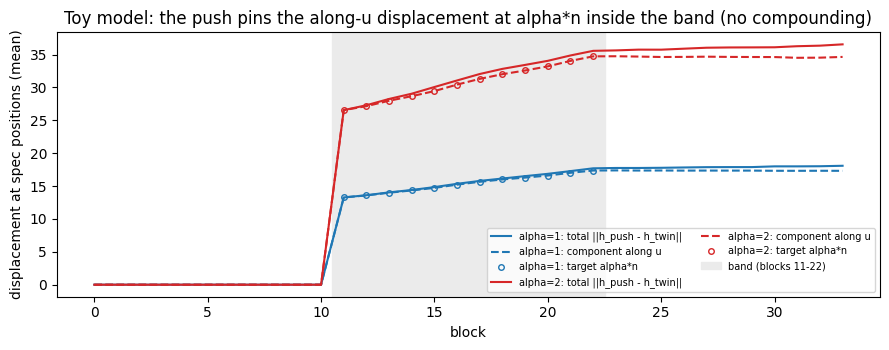

In [11]:
# notebook: a toy residual stack standing in for Gemma's 34 decoder blocks (same width, same band, same hooks)
torch.manual_seed(0)


class ToyBlock(torch.nn.Module):
    """h -> h + up(tanh(down(h))); returns a tuple, like a Hugging Face decoder layer."""
    def __init__(self, d: int, rank: int) -> None:
        super().__init__()
        self.down = torch.nn.Linear(d, rank)
        self.up = torch.nn.Linear(rank, d)

    def forward(self, h: torch.Tensor) -> tuple[torch.Tensor]:
        return (h + self.up(torch.tanh(self.down(h))),)


toy_layers = torch.nn.ModuleList([ToyBlock(D_MODEL, TOY_RANK) for _ in range(N_LAYERS)])


@torch.no_grad()
def toy_forward(x: torch.Tensor, edits=None, capture=None) -> torch.Tensor:
    with block_hooks(toy_layers, edits, capture):
        h = x
        for blk in toy_layers:
            h = blk(h)[0]
    return h


def keep(store: dict[int, torch.Tensor], l: int, sl=slice(None)) -> Callable[[torch.Tensor], None]:
    def g(h: torch.Tensor) -> None:
        store[l] = h[sl].float().clone()
    return g


x = torch.randn(1, TOY_P, D_MODEL)
x[..., :N_MASSIVE] += TOY_MASSIVE                   # 5 massive channels, as in Gemma's residual stream
a, b = TOY_SPEC

# clean twin states at the spec positions (engine_gemma.clean_states) and the push unit (units.unit_n, toy ratio)
S_ref: dict[int, torch.Tensor] = {}
toy_forward(x, capture={l: keep(S_ref, l, (0, slice(a, b))) for l in CAPTURE_BLOCKS})
n = {l: TOY_R * ox_norm(S_ref[l]) for l in BAND}          # outlier-excluded unit (adopted, D3)
n_plain = {l: TOY_R * S_ref[l].norm(dim=-1) for l in BAND}  # committed-plan unit (diagnostic)

# a batch of 4 identical prompts: alpha 0, 0, 1, 2 along the escape directions 9001 / 9002 (gpu_tests.push_spec)
B = 4
alphas = [0.0, 0.0, 1.0, 2.0]
dirs = [None, None, seed_dir(9001), seed_dir(9002)]
U = torch.zeros(B, D_MODEL, dtype=torch.float32)
for i, d in enumerate(dirs):
    if d is not None:
        U[i] = torch.tensor(d)
alpha = torch.tensor(alphas, dtype=torch.float32)
edits = make_push_edits(BAND, a, b, U, alpha, n, {l: S_ref[l] for l in BAND})

xb = x.expand(B, -1, -1).contiguous()
H_push: dict[int, torch.Tensor] = {}
H_none: dict[int, torch.Tensor] = {}
out_push = toy_forward(xb, edits, {l: keep(H_push, l) for l in range(N_LAYERS)})
out_none = toy_forward(xb, None, {l: keep(H_none, l) for l in range(N_LAYERS)})

u1 = torch.equal(out_push[:2], out_none[:2])
u2a = torch.equal(H_push[BAND[0] - 1], H_none[BAND[0] - 1])
outside = list(range(0, a)) + list(range(b, TOY_P))
u2b = torch.equal(H_push[BAND[0]][:, outside], H_none[BAND[0]][:, outside])
along = {l: ((H_push[l][:, a:b] - H_none[l][:, a:b]) * U[:, None, :]).sum(-1) for l in range(N_LAYERS)}  # [B, S]
u3 = max(float(((along[l][2:] - alpha[2:, None] * n[l][None, :]).abs() / (alpha[2:, None] * n[l][None, :])).max())
         for l in BAND)
top5 = float(((S_ref[BAND[6]] ** 2).topk(5, dim=-1).values.sum(-1) / (S_ref[BAND[6]] ** 2).sum(-1)).mean())
print(f"U1 alpha-0 rows bit-identical to the un-pushed run: {u1}")
print(f"U2 block {BAND[0] - 1} (before the band) identical: {u2a}; positions outside the spec identical at block "
      f"{BAND[0]}: {u2b}")
print(f"U3 max relative error of the displacement along u vs alpha*n over the band: {u3:.2e} (Gemma, bf16: 2e-4)")
print(f"toy states: top-5 channels carry {100 * top5:.1f}% of ||h||^2 at block {BAND[6]}; the plain unit r*||h|| is "
      f"{float((n_plain[BAND[6]] / n[BAND[6]]).mean()):.1f}x the outlier-excluded unit")
assert u1 and u2a and u2b and u3 < 1e-4

# realised displacement per block (cf. the realised_disp logged for every Gemma row)
fig, ax = plt.subplots(figsize=(9, 3.6))
blocks = np.arange(N_LAYERS)
for row, col in ((2, "tab:blue"), (3, "tab:red")):
    tot = [float((H_push[l][row, a:b] - H_none[l][row, a:b]).norm(dim=-1).mean()) for l in blocks]
    alo = [float(along[l][row].mean()) for l in blocks]
    ax.plot(blocks, tot, "-", c=col, label=f"alpha={alphas[row]:.0f}: total ||h_push - h_twin||")
    ax.plot(blocks, alo, "--", c=col, label=f"alpha={alphas[row]:.0f}: component along u")
    ax.plot(BAND, [alphas[row] * float(n[l].mean()) for l in BAND], "o", c=col, ms=4, mfc="none",
            label=f"alpha={alphas[row]:.0f}: target alpha*n")
ax.axvspan(BAND[0] - 0.5, BAND[-1] + 0.5, color="0.92", zorder=0, label="band (blocks 11-22)")
ax.set(xlabel="block", ylabel="displacement at spec positions (mean)",
       title="Toy model: the push pins the along-u displacement at alpha*n inside the band (no compounding)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 5. The escape screen → `E_t` and MOVABLE (`src/predictors.py`)

Each task is screened against its twin's off-default share `p0` and pass rate:
- **Stage 1** (N = 10 per direction-α): a cell passes if `off_share − p0 ≥ 0.20` and `pass ≥ 0.8 × twin pass`.
- **Confirmation** (N = 30 after a 20-row top-up): both criteria must hold again, and the exact binomial tail `P(X ≥ k | 30, max(p0, 0.01))` must be < 0.05.
- **Result:** `E_t` = max over α of the share of the 8 directions confirmed, and **MOVABLE** = `E_t > 0`.

`stage1` and `confirm` below are the original functions with one notebook change. Instead of re-reading the labelled rows, they read each cell's aggregate (n, off-default count, pass rate) as committed in commit #2. The rule, the thresholds and the binomial test are unchanged, so the result must reproduce the committed `E_t` exactly.

In [12]:
def stage1(t: str) -> dict[str, Any]:
    c = pre["tasks"][t]                   # notebook: committed cell aggregates instead of rows("A", t, arm)
    D = c["D"]                            # D_final(t)["D"]: the modal correct twin label (a catalogue mode)
    p0, pt = c["p0"], c["twin_pass"]      # off_share(twin_rows(t), D), pass_rate(twin_rows(t)): the N = 50 twin
    cells, passing = {}, []
    for s in ESCAPE_SEEDS:
        for a in ALPHAS:
            rr = c["stage1_cells"][f"{s}_a{int(a)}"]        # the N = 10 stage-1 rows of this direction-alpha
            sh, pr = rr["off_share"], rr["pass"]
            ok = bool(rr["n"]) and (sh - p0 >= ESCAPE_EXCESS) and (pr >= ESCAPE_PASS_FRAC * pt)
            cells[f"{s}_a{int(a)}"] = {"n": rr["n"], "off_share": sh, "excess": sh - p0, "pass": pr, "stage1_pass": ok}
            if ok:
                passing.append((s, a))
    return {"D": D, "p0": p0, "twin_pass": pt, "n_twin": c["n_twin"], "cells": cells, "passing": passing}


def confirm(t: str) -> dict[str, Any]:
    st = stage1(t)
    D, p0, pt = st["D"], st["p0"], st["twin_pass"]
    conf = []
    cells = {}
    for (s, a) in st["passing"]:
        rr = pre["tasks"][t]["confirm_cells"][f"{s}_a{int(a)}"]   # stage 1 + the 20-row top-up (stage "AB")
        n = rr["n"]
        k = rr["k_off"]
        sh, pr = (k / n if n else float("nan")), rr["pass"]
        pb = float(stats.binom.sf(k - 1, n, max(p0, P0_FLOOR))) if n else 1.0
        ok = n >= 30 and (sh - p0 >= ESCAPE_EXCESS) and (pr >= ESCAPE_PASS_FRAC * pt) and pb < BINOM_ALPHA
        cells[f"{s}_a{int(a)}"] = {"n": n, "k_off": k, "off_share": sh, "excess": sh - p0, "pass": pr,
                                   "binom_p": pb, "confirmed": ok}
        if ok:
            conf.append((s, a))
    E = {}
    for a in ALPHAS:
        E[f"a{int(a)}"] = sum(1 for (s, aa) in conf if aa == a) / len(ESCAPE_SEEDS)
    Et = max(E.values()) if E else 0.0
    kmax = int(round(Et * len(ESCAPE_SEEDS)))
    lo, hi = stats.binomtest(kmax, len(ESCAPE_SEEDS)).proportion_ci(method="exact") if True else (0, 0)
    return {**st, "confirm_cells": cells, "confirmed": conf, "E_alpha": E, "E_t": Et, "E_t_ci95": [lo, hi],
            "movable": Et > 0, "n_directions_run": len(ESCAPE_SEEDS)}


conf = {t: confirm(t) for t in ALL_TASKS}
print(f"{'task':<5}{'D':<17}{'p0':>5}{'twin pass':>10}{'stage-1 cells passed':>22}  {'confirmed (seed, alpha)':<30}"
      f"{'E_t':>6}{'committed':>10}  MOVABLE")
for t in ALL_TASKS:
    c, p = conf[t], pre["tasks"][t]
    assert c["E_t"] == p["E_t"] and [list(x) for x in c["confirmed"]] == p["confirmed"], t
    for cell, v in c["confirm_cells"].items():  # the binomial p of every confirmation cell is re-derived
        assert abs(v["binom_p"] - p["confirm_cells"][cell]["binom_p"]) <= 1e-12 * max(1.0, v["binom_p"]), (t, cell)
    print(f"{t:<5}{c['D']:<17}{c['p0']:>5.2f}{c['twin_pass']:>10.2f}{len(c['passing']):>22}  "
          f"{str([(s, int(al)) for s, al in c['confirmed']]):<30}{c['E_t']:>6.3f}{p['E_t']:>10.3f}  {c['movable']}")
print("\nMOVABLE (predicted to obey a ban of their default):", [t for t in ALL_TASKS if conf[t]["movable"]])
print("re-derived E_t, confirmed cells and binomial p reproduce commit #2 for all 15 tasks")

task D                   p0 twin pass  stage-1 cells passed  confirmed (seed, alpha)          E_t committed  MOVABLE
T1   dfs               0.50      0.82                     2  [(9003, 1), (9003, 2)]         0.125     0.125  True
T2   dijkstra          0.00      1.00                     4  [(9004, 1), (9004, 2), (9007, 1), (9007, 2)] 0.250     0.250  True
T03  full_sort         0.00      1.00                     0  []                             0.000     0.000  False
T04  naive             0.08      1.00                     4  [(9001, 1), (9001, 2), (9003, 1), (9003, 2)] 0.250     0.250  True
T06  hash_set          0.00      1.00                     0  []                             0.000     0.000  False
T05  hash_map          0.00      1.00                     2  [(9003, 2), (9004, 2)]         0.250     0.250  True
T10  dfs               0.00      1.00                     1  [(9002, 2)]                    0.125     0.125  True
R1   greedy_end        0.00      1.00                  

## 6. The frozen analysis (`predictions/analysis_c3.py`)

This module was sha256 hash-committed in commit #2, **before any ban prompt was built**. It is copied verbatim; the only change is that hard-coded resampling counts now read the config cell. It defines:
- **C3a:** for the prediction MOVABLE → obeys:
  - balanced accuracy and a Fisher exact test;
  - exact-permutation Spearman(E_t, A_t), with Kendall τ-b beside it;
  - task-bootstrap CIs, a task-label placebo and leave-one-task-out.

  The verdict is CONFIRMED iff BA ≥ 0.8 ∧ Fisher p < 0.05 ∧ ρ ≥ 0.5, DISCONFIRMED iff BA ≤ 0.6, and INCONCLUSIVE otherwise.
- **Rivals:** a sign-oriented Spearman of each rival predictor with A_t, a paired bootstrap Δρ, and a partial Spearman.
- **C3b:** smoothed log scores of four landing forecasts on the realised ban landings.
- **C1:** rarefied correct-only Hill-1 diversity, and its best value within a pass-cost budget on the randomisation hull.

`self_test()` is the module's own check on synthetic tables (testing plan T5/T6). A perfect predictor must be CONFIRMED, an all-immovable predictor DISCONFIRMED, and so on.

In [13]:
SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}
NOT_OFF = ("invalid", "disputed")
# N_PERM, N_BOOT: set in the config cell (frozen values 100_000 and 2_000)


# ------------------------------------------------------------------------------------------------ basic statistics
def rankdata(x: np.ndarray) -> np.ndarray:
    return stats.rankdata(x, method="average")


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_spearman(x: np.ndarray, y: np.ndarray, n_perm: int = N_PERM, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    if not np.isfinite(rho):
        return {"rho": None, "p_one_sided": None, "p_two_sided": None, "n": len(x), "note": "constant input"}
    rx, ry = rankdata(x), rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    perm = np.argsort(rng.random((n_perm, len(x))), axis=1)
    rp = (rx[None, :] * ry[perm]).mean(1)
    return {"rho": rho, "p_one_sided": float((np.sum(rp >= rho - 1e-12) + 1) / (n_perm + 1)),
            "p_two_sided": float((np.sum(np.abs(rp) >= abs(rho) - 1e-12) + 1) / (n_perm + 1)), "n": len(x)}


def kendall(x, y) -> float | None:
    if len(set(x)) < 2 or len(set(y)) < 2:
        return None
    return float(stats.kendalltau(x, y, variant="b").statistic)


def balanced_accuracy(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    pos, neg = obs == 1, obs == 0
    out = {"n_pos": int(pos.sum()), "n_neg": int(neg.sum()), "n_pred_pos": int(pred.sum()),
           "n_pred_neg": int((1 - pred).sum())}
    if pos.sum() == 0 or neg.sum() == 0:
        out.update(BA=None, TPR=None, TNR=None, testable=False, note="all tasks in one compliance class")
        return out
    tpr = float((pred[pos] == 1).mean())
    tnr = float((pred[neg] == 0).mean())
    out.update(BA=(tpr + tnr) / 2, TPR=tpr, TNR=tnr, testable=True,
               single_predicted_class=bool(pred.min() == pred.max()))
    return out


def fisher(pred: list[int], obs: list[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    if (pred.min() == pred.max()) or (obs.min() == obs.max()):
        return {"table": tab, "p_two_sided": 1.0, "p_greater": 1.0, "note": "degenerate margin"}
    return {"table": tab, "p_two_sided": float(stats.fisher_exact(tab, alternative="two-sided").pvalue),
            "p_greater": float(stats.fisher_exact(tab, alternative="greater").pvalue)}


# ------------------------------------------------------------------------------------------------ C3a
def c3a(tasks: list[str], E: dict[str, float], A: dict[str, float], movable: dict[str, bool] | None = None,
        thresh: float = 0.5, seed: int = 0, n_perm: int = N_PERM, n_boot: int = N_BOOT) -> dict[str, Any]:
    tasks = [t for t in tasks if t in E and t in A and E[t] is not None and A[t] is not None]
    e = np.array([E[t] for t in tasks], float)
    a = np.array([A[t] for t in tasks], float)
    mv = np.array([int((movable or {}).get(t, E[t] > 0)) for t in tasks])
    C = (a >= thresh).astype(int)
    ba = balanced_accuracy(mv, C)
    fi = fisher(mv, C)
    sp = perm_spearman(e, a, n_perm=n_perm, seed=seed)
    kt = kendall(list(e), list(a))
    rho = sp["rho"]
    if not ba["testable"]:
        verdict = "UNTESTABLE_BA (Spearman alone)"
        if rho is not None:
            verdict += f": rho={rho:.3f}"
    else:
        b = ba["BA"]
        if b >= 0.8 and fi["p_two_sided"] < 0.05 and rho is not None and rho >= 0.5:
            verdict = "CONFIRMED"
        elif b <= 0.6:
            verdict = "DISCONFIRMED"
        else:
            verdict = "INCONCLUSIVE"
    rng = np.random.default_rng(seed + 1)
    bb, br = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(tasks), len(tasks))
        r = balanced_accuracy(mv[idx], C[idx])
        if r["BA"] is not None:
            bb.append(r["BA"])
        rr = spearman(e[idx], a[idx])
        if np.isfinite(rr):
            br.append(rr)
    boot = {"BA_ci95": [float(np.quantile(bb, 0.025)), float(np.quantile(bb, 0.975))] if bb else None,
            "rho_ci95": [float(np.quantile(br, 0.025)), float(np.quantile(br, 0.975))] if br else None,
            "n_valid_BA": len(bb), "n_valid_rho": len(br)}
    # task-label permutation placebo: shuffle the outcome across tasks
    rng = np.random.default_rng(seed + 2)
    pl_ba, pl_rho = [], []
    for _ in range(N_PLACEBO):  # frozen: range(2000)
        p = rng.permutation(len(tasks))
        r = balanced_accuracy(mv, C[p])
        if r["BA"] is not None:
            pl_ba.append(r["BA"])
        rr = spearman(e, a[p])
        if np.isfinite(rr):
            pl_rho.append(rr)
    placebo = {"BA_mean": float(np.mean(pl_ba)) if pl_ba else None,
               "BA_p_ge_observed": (float(np.mean(np.array(pl_ba) >= ba["BA"] - 1e-12)) if (pl_ba and ba["BA"] is not None)
                                    else None),
               "rho_mean": float(np.mean(pl_rho)) if pl_rho else None}
    loo = {}
    for i, t in enumerate(tasks):
        m = np.arange(len(tasks)) != i
        r = balanced_accuracy(mv[m], C[m])
        loo[t] = {"BA": r["BA"], "rho": spearman(e[m], a[m])}
    p_raw = fi["p_two_sided"]
    return {"tasks": tasks, "E_t": dict(zip(tasks, e.tolist())), "A_t": dict(zip(tasks, a.tolist())),
            "movable": dict(zip(tasks, mv.tolist())), "C_t": dict(zip(tasks, C.tolist())), "balanced_accuracy": ba,
            "fisher": fi, "spearman": sp, "kendall_tau_b": kt, "verdict": verdict, "fisher_p_raw": p_raw,
            "fisher_p_bonferroni3": min(1.0, 3 * p_raw), "bootstrap": boot, "placebo_task_permutation": placebo,
            "leave_one_task_out": loo}


# ------------------------------------------------------------------------------------------------ rivals
def partial_spearman(x, y, z) -> float | None:
    x, y, z = (rankdata(np.asarray(v, float)) for v in (x, y, z))
    if np.std(z) == 0:
        return spearman(x, y)
    rxy, rxz, ryz = (np.corrcoef(p, q)[0, 1] for p, q in ((x, y), (x, z), (y, z)))
    den = math.sqrt(max(1e-12, (1 - rxz ** 2) * (1 - ryz ** 2)))
    v = (rxy - rxz * ryz) / den
    return float(v) if np.isfinite(v) else None


def rivals(tasks: list[str], E: dict[str, float], A: dict[str, float], R: dict[str, dict[str, float | None]],
           sign: dict[str, int], seed: int = 0, n_boot: int = N_BOOT) -> dict[str, Any]:
    out = {}
    for name, vals in R.items():
        tt = [t for t in tasks if vals.get(t) is not None and E.get(t) is not None and A.get(t) is not None]
        if len(tt) < 4:
            out[name] = {"n": len(tt), "note": "too few defined tasks"}
            continue
        e = np.array([E[t] for t in tt])
        a = np.array([A[t] for t in tt])
        r = sign.get(name, 1) * np.array([vals[t] for t in tt], float)
        rho_r, rho_e = spearman(r, a), spearman(e, a)
        rng = np.random.default_rng(seed + hash(name) % 1000)
        d = []
        for _ in range(n_boot):
            idx = rng.integers(0, len(tt), len(tt))
            x1, x2 = spearman(e[idx], a[idx]), spearman(r[idx], a[idx])
            if np.isfinite(x1) and np.isfinite(x2):
                d.append(x1 - x2)
        med = np.median(r)
        pred = (r > med).astype(int)
        C = (a >= 0.5).astype(int)
        out[name] = {"n": len(tt), "rho_rival_sign_oriented": rho_r, "rho_E_t_same_tasks": rho_e,
                     "delta_rho": (rho_e - rho_r) if (np.isfinite(rho_e) and np.isfinite(rho_r)) else None,
                     "delta_rho_ci95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))] if d else None,
                     "partial_spearman_E_given_rival": partial_spearman(e, a, r),
                     "median_threshold_BA": balanced_accuracy(pred, C)["BA"], "sign": sign.get(name, 1)}
    return out


# ------------------------------------------------------------------------------------------------ C3b
def smooth(p: dict[str, float], S: list[str]) -> dict[str, float]:
    out = {m: SMOOTH["f"] * p.get(m, 0.0) + SMOOTH["uniform_S"] / len(S) for m in S}
    out["other"] = SMOOTH["other"]
    return out


def log_score(p: dict[str, float], labels: list[str], S: list[str]) -> float | None:
    ps = smooth(p, S)
    xs = [math.log(ps.get(l if l in S else "other", ps["other"])) for l in labels]
    return float(np.mean(xs)) if xs else None


def top1_hit(top: str | None, labels: list[str], S: list[str]) -> dict[str, Any]:
    c = collections.Counter(l for l in labels if l in S)
    if not c or top is None:
        return {"hit": None, "frac": None, "modal": sorted(c)[:1] if c else None}
    mx = max(c.values())
    modal = sorted(m for m, v in c.items() if v == mx)
    return {"hit": int(top in modal and len(modal) == 1) if len(modal) == 1 else int(top in modal),
            "frac": (1 / len(modal)) if top in modal else 0.0, "modal": modal}


def c3b(events: dict[str, dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """events[t] = {'S': survivors, 'labels': realised ban labels (not D/invalid/disputed), 'forecasts':
    {name: {'distribution', 'top1', 'defined'}}}."""
    names = ["push_landing", "opening_ladder", "association", "proximity"]
    per = {}
    for t, ev in events.items():
        S, labs = ev["S"], ev["labels"]
        row = {"n_realised": len(labs), "realised": dict(collections.Counter(labs))}
        for nm in names:
            f = ev["forecasts"].get(nm) or {}
            dist = f.get("distribution") if f.get("defined") else {m: 1 / len(S) for m in S}
            row[nm] = {"log_score": log_score(dist or {}, labs, S), "defined": bool(f.get("defined")),
                       **top1_hit(f.get("top1") if f.get("defined") else None, labs, S)}
        per[t] = row
    summ = {}
    for nm in names:
        ls = [v[nm]["log_score"] for v in per.values() if v[nm]["log_score"] is not None]
        hits = [v[nm]["hit"] for v in per.values() if v[nm]["hit"] is not None and v[nm]["defined"]]
        frac = [v[nm]["frac"] for v in per.values() if v[nm]["frac"] is not None and v[nm]["defined"]]
        summ[nm] = {"mean_log_score": float(np.mean(ls)) if ls else None, "n_events": len(ls),
                    "n_defined": sum(1 for v in per.values() if v[nm]["defined"]),
                    "defined_only_hit_rate": float(np.mean(hits)) if hits else None,
                    "fractional_tie_credit": float(np.mean(frac)) if frac else None}
    contest = {}
    pvals = {}
    for nm in ("push_landing", "opening_ladder"):
        dis = [t for t, v in per.items() if v[nm]["log_score"] is not None and v["association"]["log_score"] is not None
               and (events[t]["forecasts"].get(nm) or {}).get("top1") != (events[t]["forecasts"].get("association")
                                                                           or {}).get("top1")]
        diffs = [per[t][nm]["log_score"] - per[t]["association"]["log_score"] for t in dis]
        md = float(np.mean(diffs)) if diffs else None
        res = {"n_disagreeing": len(dis), "mean_diff_vs_association": md,
               "wins": bool(md is not None and md >= 0.10 and len(dis) >= 3),
               "association_wins": bool(md is not None and md <= -0.10 and len(dis) >= 3)}
        if len(dis) >= 10:
            w = stats.wilcoxon(diffs)
            res["wilcoxon_p"] = float(w.pvalue)
            pvals[nm] = float(w.pvalue)
        contest[nm] = res
    if pvals:
        order = sorted(pvals, key=pvals.get)
        for i, nm in enumerate(order):
            contest[nm]["wilcoxon_p_holm"] = min(1.0, pvals[nm] * (len(order) - i))
    # shuffled-forecast placebo: forecasts permuted across events (same survivor sets only)
    rng = np.random.default_rng(seed)
    pl = {}
    ts = list(events)
    for nm in names:
        vals = []
        for _ in range(N_PLACEBO_C3B):  # frozen: range(200)
            perm = rng.permutation(len(ts))
            s = []
            for i, t in enumerate(ts):
                src = events[ts[perm[i]]]["forecasts"].get(nm) or {}
                S = events[t]["S"]
                d = src.get("distribution") if src.get("defined") else None
                d = {m: (d or {}).get(m, 0.0) for m in S}
                tot = sum(d.values())
                d = {m: v / tot for m, v in d.items()} if tot > 0 else {m: 1 / len(S) for m in S}
                x = log_score(d, events[t]["labels"], S)
                if x is not None:
                    s.append(x)
            if s:
                vals.append(np.mean(s))
        pl[nm] = float(np.mean(vals)) if vals else None
    return {"per_event": per, "summary": summ, "contest": contest, "placebo_shuffled_mean_log_score": pl,
            "verdict": ("CONFIRMED" if any(c["wins"] for c in contest.values()) else
                        "DISCONFIRMED" if all(c.get("association_wins") for c in contest.values() if c["n_disagreeing"])
                        and any(c["n_disagreeing"] for c in contest.values()) else "INCONCLUSIVE")}


# ------------------------------------------------------------------------------------------------ C1 (descriptive)
def hill1(labels: list[str]) -> float:
    c = np.array(list(collections.Counter(labels).values()), float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    if not labels:
        return {"hill": None, "depth": 0, "flag": "no correct programs"}
    rng = np.random.default_rng(seed)
    d = min(depth, len(labels))
    arr = np.array(labels)
    hs = [hill1(list(arr[rng.choice(len(arr), d, replace=False)])) for _ in range(n_sub)]
    return {"hill": float(np.mean(hs)), "depth": d, "flag": None if d == depth else f"own depth {d}"}


def mc_hill(dist: dict[str, float], depth: int = 25, n_sub: int = N_SUB_MC, rng=None) -> float:  # frozen n_sub 300
    rng = rng or np.random.default_rng(0)
    ks = list(dist)
    p = np.array([dist[k] for k in ks], float)
    if p.sum() <= 0:
        return float("nan")
    p /= p.sum()
    draws = rng.multinomial(depth, p, size=n_sub)
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(q > 0, q * np.log(q), 0.0), axis=1)
    return float(np.mean(np.exp(h)))


def arm_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    corr = [r["label"] for r in rows if r.get("passed")]
    pr = len(corr) / n if n else float("nan")
    comp = collections.Counter(corr)
    return {"n": n, "pass": pr, "correct_comp": dict(comp), "attempt_comp": dict(collections.Counter(r["label"] for r in rows))}


def hull_best(twin: dict[str, Any], settings: list[dict[str, Any]], budget_points: float, depth: int = 25,
              grid: int = HULL_GRID, seed: int = 0) -> dict[str, Any]:  # frozen grid 21
    """Best correct-only Hill-1 on the randomisation hull (twin -> s1 -> s2 ...) within `budget_points` pass points."""
    rng = np.random.default_rng(seed)
    chain = [twin] + settings
    best = {"hill": None, "segment": None, "lambda": None, "cost": None}
    pt = twin["pass"]
    for i in range(len(chain) - 1):
        a, b = chain[i], chain[i + 1]
        for lam in np.linspace(0, 1, grid):
            pas = (1 - lam) * a["pass"] + lam * b["pass"]
            cost = max(0.0, 100 * (pt - pas))
            if cost > budget_points + 1e-9:
                continue
            mix = collections.Counter()
            for comp, w in ((a["correct_comp"], (1 - lam) * a["pass"]), (b["correct_comp"], lam * b["pass"])):
                tot = sum(comp.values())
                for k, v in comp.items():
                    mix[k] += w * v / tot if tot else 0.0
            if sum(mix.values()) <= 0:
                continue
            h = mc_hill(dict(mix), depth, rng=rng)
            if best["hill"] is None or h > best["hill"]:
                best = {"hill": h, "segment": i, "lambda": float(lam), "cost": cost}
    return best


def bootstrap_hull(arms: dict[str, list[dict[str, Any]]], knob: list[str], budget: float, n_boot: int = 200,
                   seed: int = 0) -> list[float] | None:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        res = {}
        for k in ["twin"] + knob:
            rr = arms[k]
            res[k] = arm_summary([rr[i] for i in rng.integers(0, len(rr), len(rr))])
        b = hull_best(res["twin"], [res[k] for k in knob], budget, grid=11, seed=int(rng.integers(1e9)))
        if b["hill"] is not None:
            vals.append(b["hill"])
    if not vals:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def shingles(code: str, n: int = 4) -> set[tuple[str, ...]]:
    import ast

    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    names: dict[str, str] = {}
    toks = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Name):
            names.setdefault(node.id, f"v{len(names)}")
            t += ":" + names[node.id]
        toks.append(t)
    return {tuple(toks[i:i + n]) for i in range(max(0, len(toks) - n + 1))}


def phrasing_clusters(codes: list[str], theta: float) -> int:
    sh = [shingles(c) for c in codes]
    n = len(sh)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, j in itertools.combinations(range(n), 2):
        if not sh[i] or not sh[j]:
            continue
        jac = len(sh[i] & sh[j]) / len(sh[i] | sh[j])
        if jac >= theta:
            parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})


# ------------------------------------------------------------------------------------------------ self-tests
def self_test() -> dict[str, Any]:
    """Synthetic tables with known answers (testing plan T5/T6)."""
    out = {}
    tasks = [f"t{i}" for i in range(15)]
    E = {t: (0.5 if i < 6 else 0.0) for i, t in enumerate(tasks)}
    A = {t: (0.9 if i < 6 else 0.1) for i, t in enumerate(tasks)}
    r = c3a(tasks, E, A, n_perm=20000, n_boot=300)
    out["perfect"] = {"BA": r["balanced_accuracy"]["BA"], "verdict": r["verdict"], "fisher": r["fisher"]["p_two_sided"]}
    assert r["balanced_accuracy"]["BA"] == 1.0 and r["verdict"] == "CONFIRMED", r["verdict"]
    E2 = {t: 0.0 for t in tasks}
    r2 = c3a(tasks, E2, A, n_perm=2000, n_boot=100)
    out["all_immovable"] = {"BA": r2["balanced_accuracy"]["BA"], "verdict": r2["verdict"]}
    assert r2["balanced_accuracy"]["BA"] == 0.5 and r2["verdict"] == "DISCONFIRMED"
    A3 = {t: 0.9 for t in tasks}
    r3 = c3a(tasks, E, A3, n_perm=2000, n_boot=100)
    out["one_outcome_class"] = r3["verdict"]
    assert r3["verdict"].startswith("UNTESTABLE")
    rng = np.random.default_rng(5)
    ps = []
    for k in range(40):
        Er = {t: float(rng.random()) for t in tasks}
        Ar = {t: float(rng.random()) for t in tasks}
        ps.append(perm_spearman(np.array(list(Er.values())), np.array(list(Ar.values())), n_perm=2000, seed=k)
                  ["p_one_sided"])
    out["null_p_mean"] = float(np.mean(ps))
    assert 0.3 < np.mean(ps) < 0.7, np.mean(ps)
    S = ["a", "b", "c"]
    ev = {"e1": {"S": S, "labels": ["a"] * 9 + ["b"], "forecasts": {
        "push_landing": {"defined": True, "distribution": {"a": 0.9, "b": 0.05, "c": 0.05}, "top1": "a"},
        "association": {"defined": True, "distribution": {"a": 0.1, "b": 0.8, "c": 0.1}, "top1": "b"}}}}
    for i in range(2, 5):
        ev[f"e{i}"] = ev["e1"]
    c = c3b(ev)
    out["c3b_contest"] = c["contest"]["push_landing"]
    assert c["contest"]["push_landing"]["wins"]
    out["hill_uniform4"] = hill1(["a", "b", "c", "d"])
    assert abs(out["hill_uniform4"] - 4) < 1e-9
    tw = {"pass": 1.0, "correct_comp": {"x": 50}}
    s1 = {"pass": 0.9, "correct_comp": {"x": 25, "y": 20}}
    hb = hull_best(tw, [s1], 5)
    out["hull_h5"] = hb
    assert hb["cost"] <= 5 + 1e-9 and hb["hill"] > 1.0
    return out


with np.errstate(invalid="ignore", divide="ignore"):  # notebook: silence corrcoef's 0/0 on constant ranks (-> nan)
    st = self_test()
print("frozen-analysis self-test passed:")
for k, v in st.items():
    print(f"  {k}: {v}")

frozen-analysis self-test passed:
  perfect: {'BA': 1.0, 'verdict': 'CONFIRMED', 'fisher': 0.00019980019980019985}
  all_immovable: {'BA': 0.5, 'verdict': 'DISCONFIRMED'}
  one_outcome_class: UNTESTABLE_BA (Spearman alone)
  null_p_mean: 0.45353573213393306
  c3b_contest: {'n_disagreeing': 4, 'mean_diff_vs_association': 1.5980439513007842, 'wins': True, 'association_wins': False}
  hill_uniform4: 4.0
  hull_h5: {'hill': 1.649729995173063, 'segment': 0, 'lambda': 0.5, 'cost': np.float64(5.000000000000004)}


## 7. C3a: does MOVABLE predict which bans Gemma obeys? (`src/final_analysis.py`)

**Outcome measure.** `A_t` is the **catalogue-only avoidance**: the share of the 100 ban programs (5 templates × 20 CRN slots) whose label is *another* algorithm of the task's catalogue. `C_t = 1[A_t ≥ 0.5]` means the model obeys. `outcome_table` recomputes these from each task's ban label counts; the notebook change is that it counts stored label counts instead of rows.

The cell runs, in order:
- **the primary test**;
- **the pre-registered sensitivities**;
- **the post-hoc T2 relabel.** A second blind judge, and a structural rule, read most T2 "Bellman-Ford" ban programs as array-based Dijkstra. The relabelled T2 `E_t` (0.125) is taken from `posthoc_t2_relabel.json`, because recomputing it needs the relabelled escape rows.

In [14]:
def outcome_table(pre: dict[str, Any]) -> dict[str, Any]:
    """final_analysis.outcome_table on the stored label counts of the 100 primary ban programs per task."""
    out = {}
    for t in ALL_TASKS:
        D = pre["tasks"][t]["D"]
        cat = set(pre["tasks"][t]["survivors"]) | {D}      # set(PG.modes(t)): the task's algorithm catalogue
        rec = json.loads(EVENTS[t]["metadata_outcome"])     # notebook: label counts instead of the ban rows
        n = rec["n"]
        cnt = collections.Counter(rec["composition"])
        A_t = sum(v for k, v in cnt.items() if k in cat and k != D) / n
        corr = collections.Counter(rec["correct_composition"])
        n_corr = sum(corr.values())
        corr_av = (sum(v for k, v in corr.items() if k in cat and k != D) / n_corr) if n_corr else None
        tw_def = rec["twin_default_share"]
        ban_def = cnt.get(D, 0) / n
        out[t] = {"D": D, "n": n, "A_t": A_t, "C_t": int(A_t >= 0.5), "attempted_avoidance": 1 - ban_def,
                  "other": cnt.get("other", 0) / n, "invalid": cnt.get("invalid", 0) / n,
                  "disputed": cnt.get("disputed", 0) / n, "default_share": ban_def, "pass": n_corr / n,
                  "correct_only_avoidance": corr_av, "per_template_avoidance": rec["per_template_avoidance"],
                  "composition": dict(cnt), "correct_composition": dict(corr),
                  "twin_default_share": tw_def,
                  "default_share_drop": (tw_def - ban_def) if tw_def is not None else None,
                  "flag": rec["flag"]}
    return out


ot = outcome_table(pre)
for t in ALL_TASKS:  # the recomputed outcome table equals results/bans.json
    rec = json.loads(EVENTS[t]["metadata_outcome"])
    assert abs(ot[t]["A_t"] - rec["A_t"]) < 1e-12 and ot[t]["C_t"] == rec["C_t"], t
tasks = [t for t in ALL_TASKS if t in ot]
E = {t: pre["tasks"][t]["E_t"] for t in tasks}
mv = {t: bool(pre["tasks"][t]["movable"]) for t in tasks}
At = {t: ot[t]["A_t"] for t in tasks}
primary = c3a(tasks, E, At, mv)
sens = {}


def sub(name: str, keep: list[str], Aval: dict[str, float] | None = None) -> None:
    av = Aval or At
    kk = [t for t in keep if av.get(t) is not None]
    r = c3a(kk, E, av, mv, n_perm=N_PERM_SENS, n_boot=N_BOOT_SENS)  # frozen: n_perm=20000, n_boot=1000
    sens[name] = {"n_tasks": len(kk), "BA": r["balanced_accuracy"]["BA"], "fisher_p": r["fisher"]["p_two_sided"],
                  "rho": r["spearman"]["rho"], "rho_p_one_sided": r["spearman"]["p_one_sided"],
                  "verdict": r["verdict"]}


sub("without_R2", [t for t in tasks if t != "R2"])
sub("without_T1_T2", [t for t in tasks if t not in PATH_TASKS])
sub("without_flagged_R6", [t for t in tasks if t != "R6"])
sub("correct_only_avoidance", tasks, {t: ot[t]["correct_only_avoidance"] for t in tasks})
fl = data["metadata"]["label_audit"]["flagged_tasks_below_0.85"]  # F7: 4-program blind audit agreement < 0.85
sub("without_label_audit_flagged_tasks", [t for t in tasks if t not in fl])
sens["without_label_audit_flagged_tasks"]["flagged"] = fl
# the two A_t variants that need sample-level ban rows (computed from data/samples.jsonl when the demo data was built)
sub("bans_N180_with_extra_slots", tasks,
    {t: EVENTS[t]["metadata_ban_A_t_variants"]["bans_N180_with_extra_slots"] for t in tasks})
sub("disputed_as_fallback_label", tasks,
    {t: EVENTS[t]["metadata_ban_A_t_variants"]["disputed_as_fallback_label"] for t in tasks})
sub("compliance_as_default_share_drop", tasks, {t: ot[t]["default_share_drop"] for t in tasks})
low = [t for t in tasks if (pre["tasks"][t]["rivals"].get("twin_modal_share") or 1) < 0.9]
sub("default_share_drop_twin_modal_lt_0.9", low, {t: ot[t]["default_share_drop"] for t in tasks})
# continuous fallback predictors (F6): stage-1 off-default share (max over cells)
s1 = {t: max([c["excess"] for c in pre["tasks"][t]["stage1_cells"].values()] or [0]) for t in tasks}
r_s1 = perm_spearman(np.array([s1[t] for t in tasks]), np.array([At[t] for t in tasks]), n_perm=N_PERM_SENS)
sens["post_hoc_continuous_stage1_max_excess"] = {"rho": r_s1["rho"], "p_one_sided": r_s1["p_one_sided"]}
logger.info(f"C3a: BA={primary['balanced_accuracy']['BA']} fisher={primary['fisher']['p_two_sided']} "
            f"rho={primary['spearman']['rho']} -> {primary['verdict']}")

# src/posthoc_t2.py: C3a re-run with T2's labels re-judged (judge) or re-read by the structural rule
ph = data["metadata"]["posthoc_t2_relabel"]
posthoc = {}
for name, v in ph["variants"].items():
    S = set(pre["tasks"]["T2"]["survivors"])
    comp = v["T2_ban_composition"]
    A_t2 = sum(c for l, c in comp.items() if l in S) / sum(comp.values())
    E2 = {t: pre["tasks"][t]["E_t"] for t in ALL_TASKS}
    Av = {t: ot[t]["A_t"] for t in ALL_TASKS}
    mv2 = {t: bool(pre["tasks"][t]["movable"]) for t in ALL_TASKS}
    E2["T2"], Av["T2"], mv2["T2"] = v["T2_E_t"], A_t2, v["T2_E_t"] > 0
    r = c3a(list(ALL_TASKS), E2, Av, mv2, n_perm=N_PERM_SENS, n_boot=N_BOOT_SENS)  # frozen: 20000, 1000
    posthoc[name] = {"T2_E_t": v["T2_E_t"], "T2_A_t": A_t2, "BA": r["balanced_accuracy"]["BA"],
                     "fisher_p": r["fisher"]["p_two_sided"], "rho": r["spearman"]["rho"],
                     "rho_p_one_sided": r["spearman"]["p_one_sided"], "verdict": r["verdict"],
                     "table": r["fisher"]["table"]}


def same(x: Any, y: Any, tol: float = 1e-9) -> str:
    """'=' when the notebook reproduces the reported value; '~' when it differs (smaller resampling counts / MC)."""
    if isinstance(x, (int, float)) and isinstance(y, (int, float)):
        return "=" if abs(x - y) <= tol else "~"
    return "=" if x == y else "~"


def fmt(x: Any) -> str:
    if isinstance(x, (list, tuple)):
        return "[" + ", ".join(fmt(v) for v in x) + "]"
    return f"{x:.4f}" if isinstance(x, float) else str(x)


def same_all(x: Any, y: Any) -> str:
    if isinstance(x, (list, tuple)):
        return "=" if len(x) == len(y) and all(same_all(p, q) == "=" for p, q in zip(x, y)) else "~"
    return same(x, y)


rep = REPORTED["c3a"]["primary"]
ba, fi, sp = primary["balanced_accuracy"], primary["fisher"], primary["spearman"]
print("PRIMARY C3a  (15 tasks; MOVABLE:", [t for t in tasks if mv[t]], "| obeys:", [t for t in tasks if ot[t]["C_t"]], ")")
print(f"{'quantity':<36}{'notebook':>22}{'reported':>22}")
for name, x, y in [("balanced accuracy", ba["BA"], rep["balanced_accuracy"]["BA"]),
                   ("TPR / TNR", (ba["TPR"], ba["TNR"]), (rep["balanced_accuracy"]["TPR"], rep["balanced_accuracy"]["TNR"])),
                   ("Fisher table [[TP,FP],[FN,TN]]", fi["table"], rep["fisher"]["table"]),
                   ("Fisher p (two-sided)", fi["p_two_sided"], rep["fisher"]["p_two_sided"]),
                   ("Fisher p, Bonferroni bound min(1,3p)", primary["fisher_p_bonferroni3"], rep["fisher_p_bonferroni3"]),
                   ("Spearman rho(E_t, A_t)", sp["rho"], rep["spearman"]["rho"]),
                   ("rho one-sided permutation p", sp["p_one_sided"], rep["spearman"]["p_one_sided"]),
                   ("Kendall tau-b", primary["kendall_tau_b"], rep["kendall_tau_b"]),
                   ("BA bootstrap 95% CI", primary["bootstrap"]["BA_ci95"], rep["bootstrap"]["BA_ci95"]),
                   ("rho bootstrap 95% CI", primary["bootstrap"]["rho_ci95"], rep["bootstrap"]["rho_ci95"]),
                   ("placebo: P(BA >= observed)", primary["placebo_task_permutation"]["BA_p_ge_observed"],
                    rep["placebo_task_permutation"]["BA_p_ge_observed"]),
                   ("verdict", primary["verdict"], rep["verdict"])]:
    print(f"{name:<36}{fmt(x):>22}{fmt(y):>22}  {same_all(x, y)}")

print("\nSENSITIVITIES")
print(f"{'variant':<40}{'n':>3}{'BA':>8}{'Fisher p':>10}{'rho':>8}{'p(rho)':>9}  {'verdict':<32}{'reported BA / rho':>20}")
for k, v in sens.items():
    if "BA" not in v:
        rr = REPORTED["c3a"]["sensitivities"][k]["rho"]
        print(f"{k:<40}{'':>3}{'':>8}{'':>10}{v['rho']:>8.3f}{v['p_one_sided']:>9.4f}  {'(continuous predictor)':<32}"
              f"{'rho ' + format(rr, '.3f'):>20}   {same(v['rho'], rr)}")
        continue
    rv = REPORTED["c3a"]["sensitivities"][k]
    f = lambda z, w=8, d=3: f"{z:>{w}.{d}f}" if z is not None else f"{'-':>{w}}"
    print(f"{k:<40}{v['n_tasks']:>3}{f(v['BA'])}{f(v['fisher_p'], 10)}{f(v['rho'])}{f(v['rho_p_one_sided'], 9, 4)}  "
          f"{v['verdict'][:31]:<32}{(f(rv['BA'], 6) + ' / ' + f(rv['rho'], 6).strip()):>20}  "
          f"{same(v['BA'], rv['BA'])}{same(v['rho'], rv['rho'])}")
print("\nPOST HOC: T2 relabelled (not pre-registered; the frozen primary result stands)")
for k, v in posthoc.items():
    rv = ph["variants"][k]
    print(f"  {k:<11} T2: E_t {v['T2_E_t']:.3f}, A_t {v['T2_A_t']:.2f} -> BA {v['BA']:.3f}, Fisher p {v['fisher_p']:.3f}, "
          f"rho {v['rho']:.3f} ({v['verdict']}) | reported BA {rv['BA']:.3f}, rho {rv['rho']:.3f}  "
          f"{same(v['BA'], rv['BA'])}{same(v['rho'], rv['rho'])}")

15:29:18|INFO   |C3a: BA=0.7386363636363636 fisher=0.23516483516483508 rho=0.5367198354991007 -> INCONCLUSIVE


PRIMARY C3a  (15 tasks; MOVABLE: ['T1', 'T2', 'T04', 'T05', 'T10', 'T11'] | obeys: ['T1', 'T2', 'T03', 'T05'] )
quantity                                          notebook              reported
balanced accuracy                                   0.7386                0.7386  =
TPR / TNR                                 [0.7500, 0.7273]      [0.7500, 0.7273]  =
Fisher table [[TP,FP],[FN,TN]]            [[3, 3], [1, 8]]      [[3, 3], [1, 8]]  =
Fisher p (two-sided)                                0.2352                0.2352  =
Fisher p, Bonferroni bound min(1,3p)                0.7055                0.7055  =
Spearman rho(E_t, A_t)                              0.5367                0.5367  =
rho one-sided permutation p                         0.0252                0.0252  =
Kendall tau-b                                       0.4702                0.4702  =
BA bootstrap 95% CI                       [0.4000, 0.9545]      [0.4000, 0.9545]  =
rho bootstrap 95% CI                      [0.0175, 

## 8. Rival predictors: is the push screen better than simpler signals?

Every rival is computed from the same ban-free data. Their signs are fixed in the commitment:
- **twin modal share** (−): how collapsed the default is;
- **can_max** (+): forced "write X" attempts;
- **T 1.3 off-default** (+): temperature 1.3;
- **plan-noise α1 / α2 off-default** (+): fresh random directions;
- **novelty off-default** (+): the instruction *"Write a novel algorithm for this task, one you have not seen before."*;
- **opening margin** (−): a teacher-forced opening ladder.

`Δρ = ρ(E_t) − ρ(rival)` comes with a paired task-bootstrap CI. Its seed uses Python's per-process string hash, as in the original, so the CIs vary slightly between runs.

In [15]:
names = ["twin_modal_share", "twin_modal_share_correct", "can_max", "t13_off", "novelty_off", "pn_a1_off",
         "pn_a2_off", "opening_margin"]
R = {nm: {t: pre["tasks"][t]["rivals"].get(nm) for t in tasks} for nm in names}
rv = rivals(tasks, E, At, R, pre["rival_signs"])

print(f"{'predictor':<26}{'sign':>5}{'n':>4}{'rho with A_t':>14}{'reported':>10}{'delta rho [95% CI]':>32}"
      f"{'partial rho(E_t | rival)':>26}{'median-rule BA':>16}")
print(f"{'E_t (push screen)':<26}{'+':>5}{len(tasks):>4}{primary['spearman']['rho']:>14.3f}"
      f"{REPORTED['c3a']['primary']['spearman']['rho']:>10.3f}")
for nm in sorted(rv, key=lambda k: -(rv[k].get("rho_rival_sign_oriented") or -9)):
    v, r0 = rv[nm], REPORTED["rivals"][nm]
    ci = v["delta_rho_ci95"]
    print(f"{nm:<26}{('+' if v['sign'] > 0 else '-'):>5}{v['n']:>4}{v['rho_rival_sign_oriented']:>14.3f}"
          f"{r0['rho_rival_sign_oriented']:>10.3f}{v['delta_rho']:>+12.3f} [{ci[0]:+.2f}, {ci[1]:+.2f}]"
          f"{v['partial_spearman_E_given_rival']:>26.3f}{v['median_threshold_BA']:>16.3f}  "
          f"{same(v['rho_rival_sign_oriented'], r0['rho_rival_sign_oriented'])}")

predictor                  sign   n  rho with A_t  reported              delta rho [95% CI]  partial rho(E_t | rival)  median-rule BA
E_t (push screen)             +  15         0.537     0.537
novelty_off                   +  15         0.774     0.774      -0.237 [-0.83, +0.22]                     0.521           0.739  =
pn_a2_off                     +  15         0.511     0.511      +0.026 [-0.45, +0.57]                     0.360           0.693  =
pn_a1_off                     +  15         0.473     0.473      +0.064 [-0.56, +0.72]                     0.436           0.739  =
can_max                       +  15         0.349     0.349      +0.188 [-0.41, +0.75]                     0.455           0.500  =
t13_off                       +  15         0.336     0.336      +0.201 [-0.62, +0.91]                     0.534           0.659  =
twin_modal_share              -  15         0.239     0.239      +0.298 [-0.38, +0.96]                     0.508           0.534  =
twin_modal_sha

## 9. C3b: where does an obeyed ban land?

There are 4 gated events, the tasks with `C_t = 1`. For each, every ban-free forecast commits to a distribution over the surviving algorithms:
- **push-landing:** where the confirmed escape pushes landed;
- **opening ladder:** a teacher-forced ranking of program openings;
- **association:** the algorithm the model names when asked for "the standard alternative";
- **AST proximity:** how close each survivor's code is to the default's.

Each forecast is smoothed as `p′ = 0.93 p + 0.05 uniform + 0.02 'other'` and scored by its mean log score on the realised ban landings. The pre-registered contest requires a ban-free forecast to beat association by ≥ 0.10 nats on ≥ 3 events where the two disagree.

In [16]:
events = {}
for t in tasks:
    if ot[t]["C_t"] != 1:
        continue
    D = pre["tasks"][t]["D"]
    S = pre["tasks"][t]["survivors"]
    # notebook: the realised ban labels (not D / invalid / disputed) rebuilt from the label counts of the ban rows
    realised = [l for l, c in ot[t]["composition"].items() for _ in range(c) if l not in (D,) + NOT_OFF]
    events[t] = {"S": S, "labels": realised, "forecasts": pre["tasks"][t]["forecasts"]}
c3b_res = c3b(events) if events else {"note": "no gated events (no task with C_t = 1)"}

FC = ["push_landing", "proximity", "association", "opening_ladder"]
print(f"{'event':<6}{'realised ban landings (label: count)':<44}" + "".join(f"{nm:>16}" for nm in FC))
for t, v in c3b_res["per_event"].items():
    land = ", ".join(f"{l}: {c}" for l, c in sorted(v["realised"].items(), key=lambda z: -z[1]))
    print(f"{t:<6}{land[:43]:<44}" + "".join(f"{v[nm]['log_score']:>16.3f}" for nm in FC))
print(f"{'mean':<50}" + "".join(f"{c3b_res['summary'][nm]['mean_log_score']:>16.3f}" for nm in FC))
print(f"{'reported mean':<50}" + "".join(f"{REPORTED['c3b']['summary'][nm]['mean_log_score']:>16.3f}" for nm in FC))
print(f"{'top-1 hit rate':<50}" + "".join(f"{c3b_res['summary'][nm]['defined_only_hit_rate']:>16.2f}" for nm in FC))
print(f"{'shuffled-forecast placebo':<50}" + "".join(f"{c3b_res['placebo_shuffled_mean_log_score'][nm]:>16.3f}" for nm in FC))
for nm, v in c3b_res["contest"].items():
    print(f"contest {nm} vs association: {v['n_disagreeing']} disagreeing events, mean diff "
          f"{v['mean_diff_vs_association']:+.2f} nats, wins={v['wins']}")
print("C3b verdict:", c3b_res["verdict"], "| reported:", REPORTED["c3b"]["verdict"])

event realised ban landings (label: count)            push_landing       proximity     association  opening_ladder
T1    bfs: 83                                               -0.062          -1.478          -0.234          -1.630
T2    bf_spfa: 96, other: 1                                 -0.099          -1.217          -0.986          -4.377
T03   size_k_heap: 61, quickselect: 1, heapify_po           -0.206          -1.402          -3.009          -4.531
T05   brute_force: 59                                       -0.055          -0.685          -2.863          -4.090
mean                                                        -0.105          -1.196          -1.773          -3.657
reported mean                                               -0.105          -1.196          -1.773          -3.657
top-1 hit rate                                                1.00            0.75            0.50            0.00
shuffled-forecast placebo                                   -1.135          -1.3

## 10. C1: which knob diversifies the algorithm: temperature, plan noise, or asking?

This is the experiment's direct test of *"is temperature the creativity knob?"*. It compares three knob classes:
- **plan noise**: fresh random pushes at α 1 and 2;
- **temperature**: 1.3, plus 1.6 on the movable tasks;
- **the novelty instruction**.

For each class, it reports the best **correct-only Hill-1** reachable within 5 pass points of the twin (H5). Hill-1 is the effective number of distinct correct algorithms, rarefied at depth 25. The search runs over the randomisation hull: mixtures of twin → setting and of setting → next setting.

The arms' rows are rebuilt from their (label, passed) counts. H5/P15/P20 are deterministic (seed 7) and reproduce exactly at the original counts. The rarefied Hill-1 and the bootstrap CI depend on row order or on Python's string hash, so they vary slightly.

In [17]:
def rows_from_counts(arm: dict[str, Any]) -> list[dict[str, Any]]:
    """Notebook: rebuild an arm's (label, passed) rows from its label counts (passed rows in correct_comp order)."""
    rows = [{"label": l, "passed": True} for l, c in arm["correct_comp"].items() for _ in range(c)]
    for l, c in arm["attempt_comp"].items():
        rows += [{"label": l, "passed": False} for _ in range(c - arm["correct_comp"].get(l, 0))]
    return rows


def c1_prices(pre: dict[str, Any], tasks: list[str]) -> dict[str, Any]:
    res = {}
    for t in tasks:
        arms = {k: rows_from_counts(v) for k, v in EVENTS[t]["metadata_c1_arms"].items()}  # twin, pn_a1, pn_a2, t13, novelty, t16
        arms = {k: v for k, v in arms.items() if v}
        summ = {k: arm_summary(v) for k, v in arms.items()}
        tab = {}
        pt = summ["twin"]["pass"]
        for k, s in summ.items():
            corr = [r["label"] for r in arms[k] if r.get("passed")]
            rh = rarefied_hill(corr, 25, N_SUB_RAREFY, seed=hash((t, k)) % 1000)  # frozen n_sub 1000
            tab[k] = {"n": s["n"], "pass": s["pass"], "pass_cost_points": max(0.0, 100 * (pt - s["pass"])),
                      "hill1_rarefied25": rh["hill"], "depth": rh["depth"], "flag": rh["flag"],
                      "correct_comp": s["correct_comp"], "attempt_comp": s["attempt_comp"]}
        knobs = {"PN": [k for k in ("pn_a1", "pn_a2") if k in summ],
                 "temperature": [k for k in ("t13", "t16") if k in summ],
                 "novelty": [k for k in ("novelty",) if k in summ]}
        hull = {}
        for kn, ks in knobs.items():
            if not ks:
                continue
            hull[kn] = {}
            for budget, name in ((5, "H5"), (15, "P15"), (20, "P20")):
                b = hull_best(summ["twin"], [summ[k] for k in ks], budget, seed=7)
                ci = bootstrap_hull(arms, ks, budget, n_boot=N_BOOT_HULL, seed=11) if name == "H5" else None  # frozen 100
                hull[kn][name] = {**b, "ci95": ci}
        res[t] = {"arms": tab, "hull": hull}
    return res


t0 = time.time()
c1 = c1_prices(pre, tasks)
print(f"C1 prices for {len(tasks)} tasks in {time.time() - t0:.1f}s")
RC1 = REPORTED["c1_prices_hull"]["per_task"]
print(f"{'task':<5}{'twin Hill-1':>12}{'pass':>6} | {'H5: plan noise':>18}{'temperature':>14}{'novelty':>10} | "
      f"{'reported H5 (PN / T / nov)':>28}")
for t in tasks:
    h = c1[t]["hull"]
    vals = [h[k]["H5"]["hill"] for k in ("PN", "temperature", "novelty")]
    rvals = [RC1[t]["hull"][k]["H5"]["hill"] for k in ("PN", "temperature", "novelty")]
    ci = h["PN"]["H5"]["ci95"]
    mark = "*" if t in REPORTED["c1_prices_hull"]["movable_tasks"] else " "
    print(f"{t + mark:<5}{c1[t]['arms']['twin']['hill1_rarefied25']:>12.2f}{c1[t]['arms']['twin']['pass']:>6.2f} | "
          f"{vals[0]:>8.2f} [{ci[0]:.2f},{ci[1]:.2f}]{vals[1]:>14.2f}{vals[2]:>10.2f} | "
          f"{' / '.join(f'{v:.2f}' for v in rvals):>28}  {''.join(same(x, y) for x, y in zip(vals, rvals))}")
print("* = MOVABLE task; H5 = best correct-only Hill-1 (depth 25) within 5 pass points of the twin")

C1 prices for 15 tasks in 3.0s
task  twin Hill-1  pass |     H5: plan noise   temperature   novelty |   reported H5 (PN / T / nov)
T1*          1.96  0.82 |     1.98 [1.86,2.38]          1.97      1.93 |           1.98 / 1.97 / 1.93  ===
T2*          1.00  1.00 |     1.62 [1.41,1.89]          1.00      1.96 |           1.62 / 1.00 / 1.96  ===
T03          1.00  1.00 |     1.38 [1.18,1.64]          1.10      1.61 |           1.38 / 1.10 / 1.61  ===
T04*         1.31  1.00 |     1.64 [1.43,1.86]          1.32      1.42 |           1.64 / 1.32 / 1.42  ===
T06          1.00  1.00 |     1.00 [1.00,1.00]          1.00      1.00 |           1.00 / 1.00 / 1.00  ===
T05*         1.00  1.00 |     1.10 [1.00,1.27]          1.00      1.00 |           1.10 / 1.00 / 1.00  ===
T10*         1.00  1.00 |     1.58 [1.31,1.80]          1.00      1.10 |           1.58 / 1.00 / 1.10  ===
R1           1.00  1.00 |     1.00 [1.00,1.00]          1.00      1.00 |           1.00 / 1.00 / 1.00  ===
T08          

## 11. Results

The six panels show the re-run:
- **(a)** `E_t` vs `A_t` per task: the C3a test;
- **(b)** the predicted × observed confusion matrix;
- **(c)** how well each rival predictor tracks ban compliance;
- **(d)** what Gemma writes when its default is banned;
- **(e)** C3b: where an obeyed ban lands, by forecast;
- **(f)** C1: algorithm diversity within 5 pass points, by knob.

The final table lists the headline numbers next to the values the experiment reported.

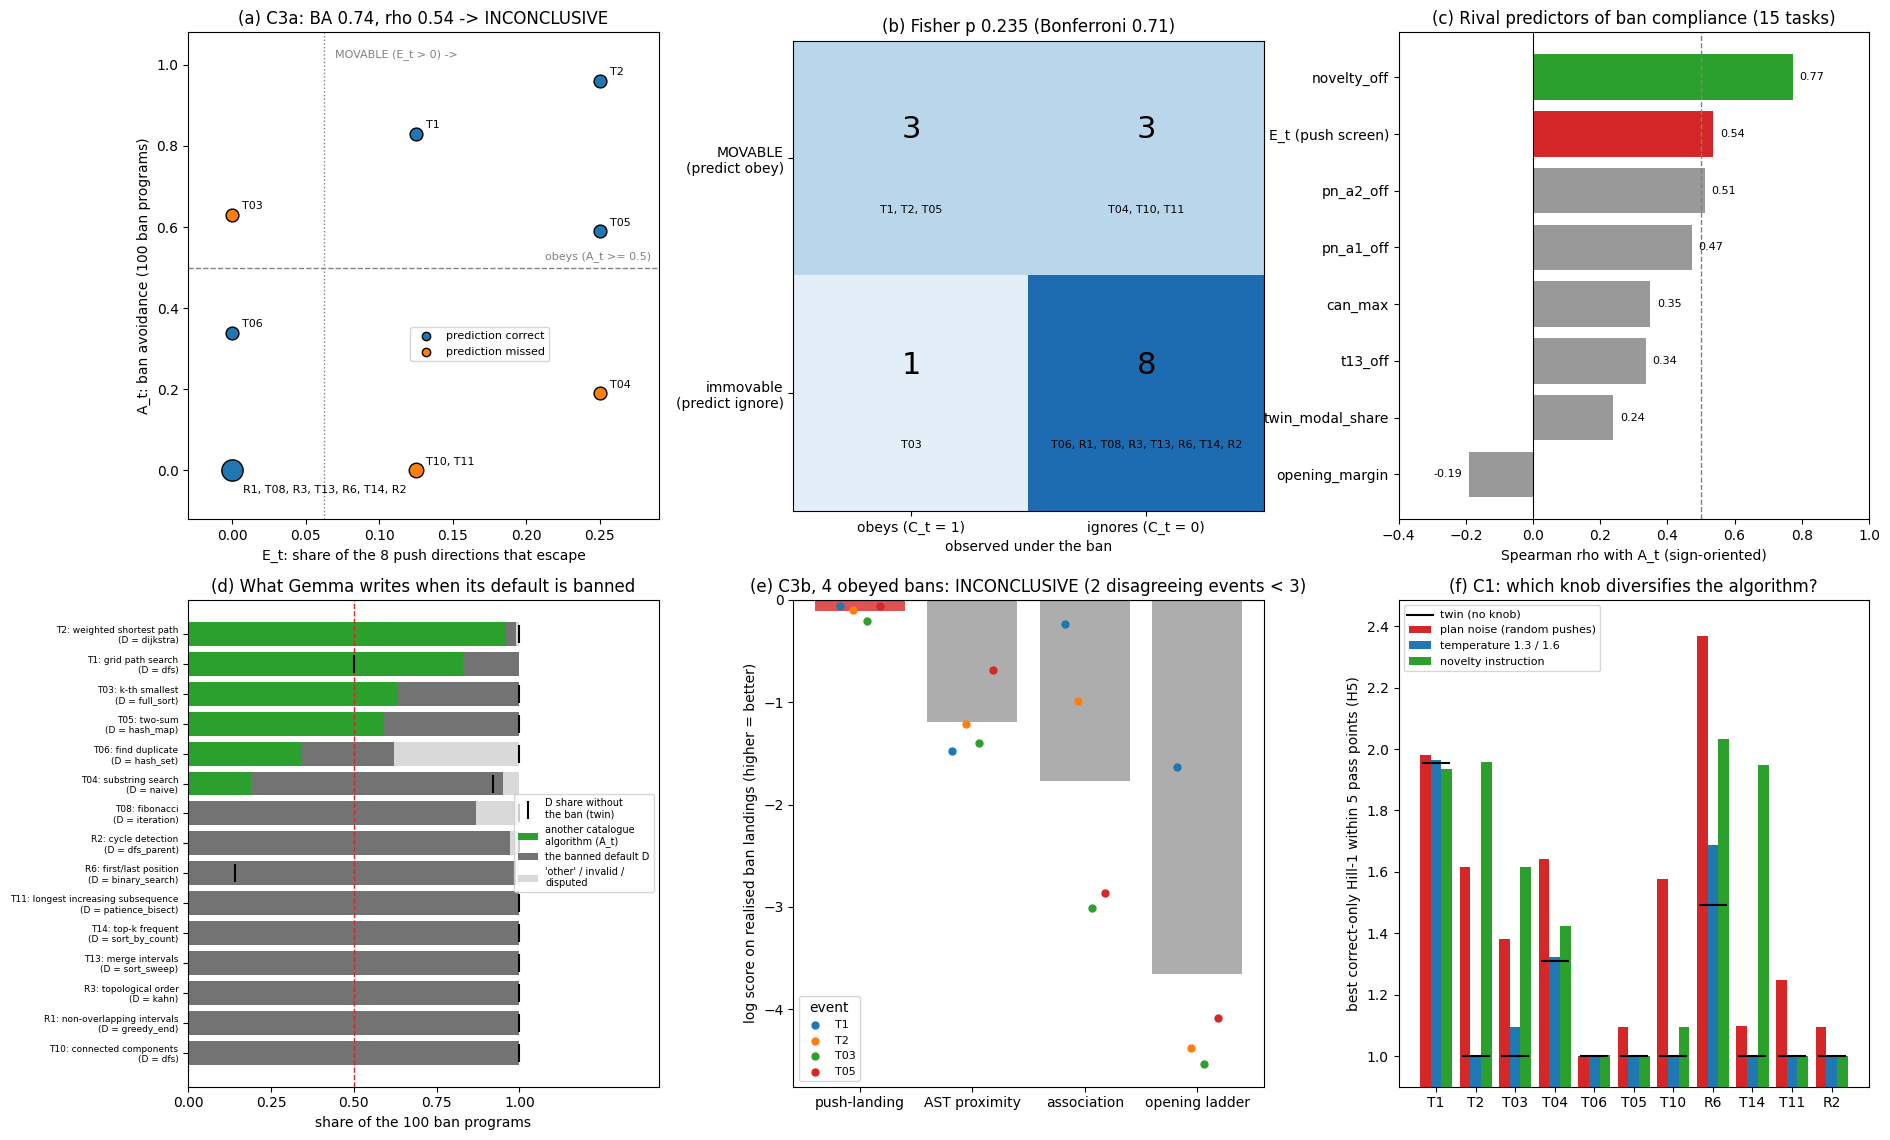

headline quantity                           notebook        reported
C3a balanced accuracy                         0.7386          0.7386  =
C3a Fisher p (two-sided)                      0.2352          0.2352  =
C3a Spearman rho                              0.5367          0.5367  =
C3a rho one-sided permutation p               0.0252          0.0252  =
C3a Kendall tau-b                             0.4702          0.4702  =
C3a verdict                             INCONCLUSIVE    INCONCLUSIVE  =
sensitivity without T1/T2: BA                 0.6136          0.6136  =
post hoc T2 judge relabel: BA                 0.6667          0.6667  =
rival novelty_off: rho                        0.7735          0.7735  =
C3b push-landing mean log score              -0.1054         -0.1054  =
C3b association mean log score               -1.7730         -1.7730  =
C3b verdict                             INCONCLUSIVE    INCONCLUSIVE  =
C1 T2 H5 plan noise                           1.6170          1.617

In [18]:
fig, axs = plt.subplots(2, 3, figsize=(19, 11.5))

# (a) E_t vs A_t
ax = axs[0, 0]
groups = collections.defaultdict(list)
for t in tasks:
    groups[(primary["E_t"][t], primary["A_t"][t])].append(t)
for (e, av), ts in groups.items():
    hit = primary["movable"][ts[0]] == primary["C_t"][ts[0]]
    ax.scatter(e, av, s=60 + 25 * len(ts), c="tab:blue" if hit else "tab:orange", edgecolor="k", zorder=3)
    ax.annotate(", ".join(ts), (e, av), textcoords="offset points", xytext=(8, -16) if len(ts) > 2 else (7, 4),
                fontsize=8)
ax.axhline(COMPLY_THRESH, ls="--", c="gray", lw=1)
ax.axvline(0.0625, ls=":", c="gray", lw=1)
ax.text(0.07, 1.02, "MOVABLE (E_t > 0) ->", fontsize=8, color="gray")
ax.text(0.285, COMPLY_THRESH + 0.02, "obeys (A_t >= 0.5)", fontsize=8, color="gray", ha="right")
ax.scatter([], [], c="tab:blue", edgecolor="k", label="prediction correct")
ax.scatter([], [], c="tab:orange", edgecolor="k", label="prediction missed")
ax.legend(loc="center", bbox_to_anchor=(0.62, 0.36), fontsize=8)
ax.set(xlim=(-0.03, 0.29), ylim=(-0.12, 1.08), xlabel="E_t: share of the 8 push directions that escape",
       ylabel="A_t: ban avoidance (100 ban programs)",
       title=f"(a) C3a: BA {primary['balanced_accuracy']['BA']:.2f}, rho {primary['spearman']['rho']:.2f} "
             f"-> {primary['verdict']}")

# (b) confusion matrix
ax = axs[0, 1]
tab = np.array(primary["fisher"]["table"])
ax.imshow(tab, cmap="Blues", vmin=0, vmax=tab.max() * 1.3)
cell_tasks = [[[t for t in tasks if primary["movable"][t] == pm and primary["C_t"][t] == oc] for oc in (1, 0)]
              for pm in (1, 0)]
for i in range(2):
    for j in range(2):
        ax.text(j, i - 0.12, str(tab[i, j]), ha="center", va="center", fontsize=22)
        ax.text(j, i + 0.22, ", ".join(cell_tasks[i][j]), ha="center", va="center", fontsize=8, wrap=True)
ax.set_xticks([0, 1], ["obeys (C_t = 1)", "ignores (C_t = 0)"])
ax.set_yticks([0, 1], ["MOVABLE\n(predict obey)", "immovable\n(predict ignore)"])
ax.set(xlabel="observed under the ban", title=f"(b) Fisher p {primary['fisher']['p_two_sided']:.3f} "
                                              f"(Bonferroni {primary['fisher_p_bonferroni3']:.2f})")

# (c) rivals
ax = axs[0, 2]
rho_list = [("E_t (push screen)", primary["spearman"]["rho"])] + \
           [(nm, v["rho_rival_sign_oriented"]) for nm, v in rv.items() if nm != "twin_modal_share_correct"]
rho_list.sort(key=lambda z: z[1])
ax.barh([n_ for n_, _ in rho_list], [r_ for _, r_ in rho_list],
        color=["tab:red" if n_.startswith("E_t") else ("tab:green" if n_ == "novelty_off" else "0.6") for n_, _ in rho_list])
for i, (n_, r_) in enumerate(rho_list):
    ax.text(r_ + (0.02 if r_ >= 0 else -0.02), i, f"{r_:.2f}", va="center", ha="left" if r_ >= 0 else "right", fontsize=8)
ax.axvline(0, c="k", lw=0.8)
ax.axvline(0.5, ls="--", c="gray", lw=1)
ax.set(xlim=(-0.4, 1.0), xlabel="Spearman rho with A_t (sign-oriented)",
       title="(c) Rival predictors of ban compliance (15 tasks)")

# (d) what Gemma writes under the ban
ax = axs[1, 0]
order = sorted(tasks, key=lambda t: (ot[t]["A_t"], -ot[t]["default_share"]))
avoid = [ot[t]["A_t"] for t in order]
dflt = [ot[t]["default_share"] for t in order]
rest = [1 - x - y for x, y in zip(avoid, dflt)]
ylab = [f"{t}: {TITLES[t]}\n(D = {ot[t]['D']})" for t in order]
ax.barh(ylab, avoid, color="tab:green", label="another catalogue\nalgorithm (A_t)")
ax.barh(ylab, dflt, left=avoid, color="0.45", label="the banned default D")
ax.barh(ylab, rest, left=[x + y for x, y in zip(avoid, dflt)], color="0.85", label="'other' / invalid /\ndisputed")
ax.scatter([ot[t]["twin_default_share"] for t in order], range(len(order)), marker="|", s=150, c="k", zorder=3,
           label="D share without\nthe ban (twin)")
ax.axvline(COMPLY_THRESH, ls="--", c="tab:red", lw=1)
ax.tick_params(axis="y", labelsize=6.5)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set(xlim=(0, 1.42), xlabel="share of the 100 ban programs", title="(d) What Gemma writes when its default is banned")
ax.legend(fontsize=7, loc="center right")

# (e) C3b log scores
ax = axs[1, 1]
xs = np.arange(len(FC))
ax.bar(xs, [c3b_res["summary"][nm]["mean_log_score"] for nm in FC], color=["tab:red", "0.6", "0.6", "0.6"], alpha=0.8)
for k, (t, v) in enumerate(c3b_res["per_event"].items()):
    ax.scatter(xs + (k - 1.5) * 0.12, [v[nm]["log_score"] for nm in FC], s=25, zorder=3, label=t)
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(xs, ["push-landing", "AST proximity", "association", "opening ladder"])
ax.set(ylabel="log score on realised ban landings (higher = better)",
       title=f"(e) C3b, 4 obeyed bans: {c3b_res['verdict']} "
             f"({c3b_res['contest']['push_landing']['n_disagreeing']} disagreeing events < 3)")
ax.legend(fontsize=8, title="event")

# (f) C1 diversity within 5 pass points
ax = axs[1, 2]
sel = [t for t in tasks if max(c1[t]["hull"][k]["H5"]["hill"] for k in ("PN", "temperature", "novelty")) > 1.0 + 1e-6
       or c1[t]["arms"]["twin"]["hill1_rarefied25"] > 1.0 + 1e-6]
xs = np.arange(len(sel))
for k, (kn, col) in enumerate((("PN", "tab:red"), ("temperature", "tab:blue"), ("novelty", "tab:green"))):
    hv = [c1[t]["hull"][kn]["H5"]["hill"] for t in sel]
    lab = {"PN": "plan noise (random pushes)", "temperature": "temperature 1.3 / 1.6", "novelty": "novelty instruction"}[kn]
    ax.bar(xs + (k - 1) * 0.27, hv, width=0.27, color=col, label=lab)
ax.scatter(xs, [c1[t]["arms"]["twin"]["hill1_rarefied25"] for t in sel], marker="_", s=400, c="k", zorder=3,
           label="twin (no knob)")
ax.set_xticks(xs, sel)
ax.set(ylim=(0.9, None), ylabel="best correct-only Hill-1 within 5 pass points (H5)",
       title="(f) C1: which knob diversifies the algorithm?")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# reproduction summary
rep_c3a = REPORTED["c3a"]
summary = [
    ("C3a balanced accuracy", primary["balanced_accuracy"]["BA"], rep_c3a["primary"]["balanced_accuracy"]["BA"]),
    ("C3a Fisher p (two-sided)", primary["fisher"]["p_two_sided"], rep_c3a["primary"]["fisher"]["p_two_sided"]),
    ("C3a Spearman rho", primary["spearman"]["rho"], rep_c3a["primary"]["spearman"]["rho"]),
    ("C3a rho one-sided permutation p", primary["spearman"]["p_one_sided"], rep_c3a["primary"]["spearman"]["p_one_sided"]),
    ("C3a Kendall tau-b", primary["kendall_tau_b"], rep_c3a["primary"]["kendall_tau_b"]),
    ("C3a verdict", primary["verdict"], rep_c3a["primary"]["verdict"]),
    ("sensitivity without T1/T2: BA", sens["without_T1_T2"]["BA"], rep_c3a["sensitivities"]["without_T1_T2"]["BA"]),
    ("post hoc T2 judge relabel: BA", posthoc["judge"]["BA"], ph["variants"]["judge"]["BA"]),
    ("rival novelty_off: rho", rv["novelty_off"]["rho_rival_sign_oriented"],
     REPORTED["rivals"]["novelty_off"]["rho_rival_sign_oriented"]),
    ("C3b push-landing mean log score", c3b_res["summary"]["push_landing"]["mean_log_score"],
     REPORTED["c3b"]["summary"]["push_landing"]["mean_log_score"]),
    ("C3b association mean log score", c3b_res["summary"]["association"]["mean_log_score"],
     REPORTED["c3b"]["summary"]["association"]["mean_log_score"]),
    ("C3b verdict", c3b_res["verdict"], REPORTED["c3b"]["verdict"]),
    ("C1 T2 H5 plan noise", c1["T2"]["hull"]["PN"]["H5"]["hill"], RC1["T2"]["hull"]["PN"]["H5"]["hill"]),
    ("C1 T2 H5 temperature", c1["T2"]["hull"]["temperature"]["H5"]["hill"], RC1["T2"]["hull"]["temperature"]["H5"]["hill"]),
    ("C1 T2 H5 novelty", c1["T2"]["hull"]["novelty"]["H5"]["hill"], RC1["T2"]["hull"]["novelty"]["H5"]["hill"]),
]
print(f"{'headline quantity':<36}{'notebook':>16}{'reported':>16}")
for name, x, y in summary:
    print(f"{name:<36}{fmt(x):>16}{fmt(y):>16}  {same(x, y)}")
print("\n'=' reproduced exactly; '~' differs: a Monte-Carlo quantity, run with fewer draws than the original or seeded "
      "by Python's per-process string hash / the row order")